In [1]:
import os
import pickle
import regionmask
import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from shapely.geometry import box
from scipy.stats import ttest_ind

In [2]:
def to_month_start_on_time(ds: xr.Dataset) -> xr.Dataset:
    """
    Force ds.time to the first day of each month.
    Works for both ERA5 and GRACE monthly data.
    """
    t = pd.to_datetime(ds.indexes["time"]).to_period("M").to_timestamp()  # month-end by default
    t = t - pd.offsets.MonthEnd(1) + pd.offsets.Day(1)  # shift to first day
    return ds.assign_coords(time=t)

In [3]:
out = "/home/mgurazada/snowdroughts_thirst/data/era5_monthly/era5_monthly_processed"
era5_path = os.path.join(out, "era5_data.nc")
era5_data = xr.open_dataset(era5_path)
era5_data = era5_data.sel(time=slice("1950-04-01", None))
era5_data = to_month_start_on_time(era5_data)
ppt = era5_data['ppt']
ppt

<xarray.DataArray 'ppt' (time: 897, lat: 721, lon: 1440)> Size: 4GB
[931301280 values with dtype=float32]
Coordinates:
  * time     (time) datetime64[ns] 7kB 1950-04-01 1950-05-01 ... 2024-12-01
  * lat      (lat) float64 6kB -90.0 -89.75 -89.5 -89.25 ... 89.5 89.75 90.0
  * lon      (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
Attributes:
    units:              mm
    description:        monthly total precipitation
    dimensions:         lon lat time
    grid_mapping:       crs
    coordinate_system:  WGS84,EPSG:4326

In [4]:
hb = gpd.read_file("/home/mgurazada/snowdroughts_thirst/data/hydrobasins/hydrobasins_global_lev04.shp")

# restrict to 0–60N if you are using that domain

bbox_geom = box(-180, 0, 180, 60)
hb = hb[hb.geometry.intersects(bbox_geom)].copy()

# simplify + fix geometry
hb["geometry"] = hb.geometry.simplify(0.01, preserve_topology=True)
hb["geometry"] = hb.geometry.buffer(0)

# dissolve per MAIN_BAS
geoms   = []
names   = []
abbrevs = []
main_ids_valid = []

for mid in np.sort(hb["MAIN_BAS"].unique()):
    basin = hb[hb["MAIN_BAS"] == mid]

    geom = basin.geometry.union_all().buffer(0)

    if geom.is_empty:
        continue

    geoms.append(geom)
    names.append(f"basin_{mid}")
    abbrevs.append(str(mid))
    main_ids_valid.append(mid)

regions = regionmask.Regions(geoms, names=names, abbrevs=abbrevs)

# map basin → region index
basin_to_region_index = {bid: i for i, bid in enumerate(main_ids_valid)}

In [5]:
mask_era5 = regions.mask_3D(
    era5_data["lon"],
    era5_data["lat"],
    drop=False
)
mask_era5

/home/mgurazada/.conda/envs/myenv/lib/python3.11/site-packages/regionmask/core/mask.py:406: UserWarning: Detected overlapping regions. As of v0.11.0 these are correctly taken into account. Note, however, that a different mask is returned than with older versions of regionmask. To suppress this warning, set `overlap=True` (to restore the old, incorrect, behaviour, set `overlap=False`).
  warnings.warn(


<xarray.DataArray 'mask' (region: 602, lat: 721, lon: 1440)> Size: 625MB
array([[[False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        ...,
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False]],

       [[False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        ...,
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False]],

       [[False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        ...,
...
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False]],

       [[False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        ...,
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False]],

       [[False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        ...,
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False]]],
      shape=(602, 721, 1440))
Coordinates:
  * region   (region) int64 5kB 0 1 2 3 4 5 6 7 ... 595 596 597 598 599 600 601
  * lat      (lat) float64 6kB -90.0 -89.75 -89.5 -89.25 ... 89.5 89.75 90.0
  * lon      (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
    abbrevs  (region) <U10 24kB '1040000010' '1040003990' ... '9040005890'
    names    (region) <U16 39kB 'basin_1040000010' ... 'basin_9040005890'
Attributes:
    standard_name:  region

In [6]:
print("n MAIN_BAS ids:", len(main_ids_valid))
print("n regions:", len(regions))
print("mask_era5 n_regions:", mask_era5.sizes["region"])

n MAIN_BAS ids: 602
n regions: 602
mask_era5 n_regions: 602


In [7]:
# monthly MODIS snow-cover climatology and turning it into one continuous winter snow-fraction for Dec-Mar.
    
# Load MODIS snow climatology
# Select winter months (Dec–Mar)
# Calculate mean winter snow-cover fraction (Dec–Mar)
# load snow mask climatology (MODIS NSIDC)
snow_path = "/home/mgurazada/snowdroughts_thirst/data/snow_cover/data/snow_mask_monthly_climatology/modis_nsidc_snow_fraction_monthly_0p05deg_v1.nc"
snow = xr.open_dataset(snow_path)

snow_clim = snow["snow_fraction"]

# pick snow months Dec–Mar
snow_winter = snow_clim.sel(month=[12, 1, 2, 3])

# Mean Dec–Mar climatological snow fraction
winter_snow_frac = snow_winter.mean(dim="month")
winter_snow_frac

<xarray.DataArray 'snow_fraction' (lat: 3600, lon: 7200)> Size: 104MB
array([[ 1.,  1.,  1., ...,  1.,  1.,  1.],
       [ 1.,  1.,  1., ...,  1.,  1.,  1.],
       [ 1.,  1.,  1., ...,  1.,  1.,  1.],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]],
      shape=(3600, 7200), dtype=float32)
Coordinates:
  * lat      (lat) float64 29kB -89.97 -89.92 -89.88 ... 89.88 89.93 89.98
  * lon      (lon) float64 58kB -180.0 -179.9 -179.9 ... 179.9 179.9 180.0

In [8]:
# Load cropland
# Standardize coordinates (x/y → lon/lat)
# Ensure latitude ordering
# Convert cropland to boolean presence

# load cropland (2019)
crop_path = "/home/mgurazada/snowdroughts_thirst/data/cropland/Global_cropland_3km_2019.nc"
crop = xr.open_dataset(crop_path)
crop_var_name = list(crop.data_vars)[1]
cropland = crop[crop_var_name]  # e.g., cropland

# If coordinates are named x/y, rename to lon/lat once:
if "x" in cropland.dims and "y" in cropland.dims:
    cropland = cropland.rename({"y": "lat", "x": "lon"})

# sort latitude ascending
if (cropland.lat.diff("lat") < 0).any():
    cropland = cropland.sortby("lat")

print(cropland.min().item(), cropland.max().item())

# Convert cropland percentage (0–100) to fraction (0–1)
cropland_frac = cropland / 100.0

# Safety check
cropland_frac = cropland_frac.clip(0, 1)

cropland_frac.attrs["long_name"] = "Global cropland fraction"
cropland_frac.attrs["units"] = "fraction (0-1)"
cropland_frac.attrs["source"] = "GLAD Global Cropland Extent 2019"

print(
    cropland_frac.min().item(),
    cropland_frac.max().item()
)

0.0 100.0
0.0 1.0


In [9]:
# ============================================================
# ERA5 grid basin mask
# ============================================================

mask3d_era5 = regions.mask_3D(
    era5_data["lon"],
    era5_data["lat"],
    drop=False
).load()

overlap_count = mask3d_era5.sum(dim="region")

print(
    "Maximum overlapping basins:",
    overlap_count.max().item()
)

n_overlap_cells = (overlap_count > 1).sum().item()

print(
    "ERA5 cells belonging to >1 basin:",
    n_overlap_cells
)


# ============================================================
# ERA5 latitude-dependent area weights
# ============================================================

lat_weights_era5 = np.cos(
    np.deg2rad(era5_data["lat"])
)

w2d_era5 = xr.DataArray(
    lat_weights_era5,
    coords={"lat": era5_data["lat"]},
    dims=["lat"]
).broadcast_like(
    era5_data.isel(time=0, drop=True)
)

w2d_era5 = w2d_era5.load()

print("mask3d_era5:", mask3d_era5.dims, mask3d_era5.shape)
print("w2d_era5:", w2d_era5.dims, w2d_era5.shape)

Maximum overlapping basins: 2
ERA5 cells belonging to >1 basin: 16
mask3d_era5: ('region', 'lat', 'lon') (602, 721, 1440)
w2d_era5: ('lat', 'lon') (721, 1440)


/home/mgurazada/.conda/envs/myenv/lib/python3.11/site-packages/regionmask/core/mask.py:406: UserWarning: Detected overlapping regions. As of v0.11.0 these are correctly taken into account. Note, however, that a different mask is returned than with older versions of regionmask. To suppress this warning, set `overlap=True` (to restore the old, incorrect, behaviour, set `overlap=False`).
  warnings.warn(


In [10]:
# The time coordinate is standardized to the first day of each month.
def first_day_each_month(ds: xr.Dataset) -> xr.Dataset:
    """
    Force ds.time to the first day of each month. 
    Works for both ERA5 and GRACE monthly data.
    """
    t = pd.to_datetime(ds.indexes["time"]).to_period("M").to_timestamp()  # month-end by default
    t = t - pd.offsets.MonthEnd(1) + pd.offsets.Day(1)  # shift to first day
    return ds.assign_coords(time=t)#loading era5 data

    
era5_land_path = os.path.join("/home/mgurazada/snowdroughts_thirst/data/era5_land_swe", "era5_land_swe_mm_1950_2024_processed.nc")
era5_land_data = xr.open_dataset(era5_land_path)
era5_land_data = first_day_each_month(era5_land_data)
era5_land_data

# ============================================================
# ERA5-Land grid basin mask for SWE
# ============================================================

mask3d_era5_land = regions.mask_3D(
    era5_land_data["lon"],
    era5_land_data["lat"],
    drop=False
).load()

overlap_count_land = mask3d_era5_land.sum(dim="region")

print(
    "Maximum overlapping basins on ERA5-Land grid:",
    overlap_count_land.max().item()
)

n_overlap_cells_land = (
    overlap_count_land > 1
).sum().item()

print(
    "ERA5-Land cells belonging to >1 basin:",
    n_overlap_cells_land
)


# ============================================================
# ERA5-Land latitude-dependent area weights
# ============================================================

lat_weights_era5_land = np.cos(
    np.deg2rad(era5_land_data["lat"])
)

w2d_era5_land = xr.DataArray(
    lat_weights_era5_land,
    coords={"lat": era5_land_data["lat"]},
    dims=["lat"]
).broadcast_like(
    era5_land_data.isel(time=0, drop=True)
)

w2d_era5_land = w2d_era5_land.load()

print(
    "mask3d_era5_land:",
    mask3d_era5_land.dims,
    mask3d_era5_land.shape
)

print(
    "w2d_era5_land:",
    w2d_era5_land.dims,
    w2d_era5_land.shape
)

/home/mgurazada/.conda/envs/myenv/lib/python3.11/site-packages/regionmask/core/mask.py:406: UserWarning: Detected overlapping regions. As of v0.11.0 these are correctly taken into account. Note, however, that a different mask is returned than with older versions of regionmask. To suppress this warning, set `overlap=True` (to restore the old, incorrect, behaviour, set `overlap=False`).
  warnings.warn(


Maximum overlapping basins on ERA5-Land grid: 2
ERA5-Land cells belonging to >1 basin: 109
mask3d_era5_land: ('region', 'lat', 'lon') (602, 901, 3600)
w2d_era5_land: ('lat', 'lon') (901, 3600)


In [11]:
# load the same data

snow_on_era5_land = xr.open_dataarray(
    "/home/mgurazada/snowdroughts_thirst/data/regridded/modis_winter_snow_fraction_on_era5_land.nc"
)

crop_on_era5 = xr.open_dataarray(
    "/home/mgurazada/snowdroughts_thirst/data/regridded/glad_cropland_fraction_on_era5.nc"
)

In [12]:
print(
    "Snow NaNs:",
    int(snow_on_era5_land.isnull().sum())
)

print(
    "Crop NaNs:",
    int(crop_on_era5.isnull().sum())
)

Snow NaNs: 2057624
Crop NaNs: 0


In [13]:
# ============================================================
# Load previously screened eligible basins
# ============================================================

eligible_df = pd.read_csv(
    "/home/mgurazada/snowdroughts_thirst/data/eligible_main_bas.csv"
)

eligible_main_bas = (
    eligible_df["MAIN_BAS"]
    .astype("int64")
    .tolist()
)

eligible_set = set(
    eligible_main_bas
)

In [14]:
# ============================================================
# Basin-level monthly precipitation
# ERA5 grid
# ============================================================

SPATIAL_DIM = "z"

# Stack precipitation and area weights once
ppt_s = ppt.stack({SPATIAL_DIM: ("lat", "lon")})

w_s_era5 = w2d_era5.stack({SPATIAL_DIM: ("lat", "lon")})

eligible_regions = np.array([
    basin_to_region_index[bid]
    for bid in eligible_set
    if bid in basin_to_region_index
])

# ============================================================
# Calculate precipitation basin-by-basin
# ============================================================

ppt_list = []

for r in eligible_regions:

    # Basin mask on ERA5 grid
    basin_mask_s = mask3d_era5.sel(region=r).stack({SPATIAL_DIM: ("lat", "lon")})

    # Cells inside this basin
    idx = np.where(basin_mask_s.values)[0]

    # Latitude-area weights
    weights_r = w_s_era5.isel(z=idx)

    # Monthly precipitation in basin cells
    ppt_r = ppt_s.isel(z=idx)

    # NaN-aware weights
    valid_weights = weights_r.where(ppt_r.notnull())

    # Area-weighted basin mean precipitation
    basin_mean = (
        (ppt_r * valid_weights).sum(dim="z", skipna=True)
        /
        valid_weights.sum(dim="z")
    )

    basin_mean = basin_mean.expand_dims(region=[r])

    ppt_list.append(basin_mean)


ppt_all = xr.concat(
    ppt_list,
    dim="region"
)

In [15]:
# ============================================================
# Convert stacked precipitation result to MAIN_BAS dictionary
# ============================================================

ppt_by_basin = {}

for r in ppt_all["region"].values:

    bid = main_ids_valid[int(r)]

    ppt_by_basin[bid] = ppt_all.sel(
        region=r
    )

In [16]:
def water_year(time):
    year = time.dt.year
    month = time.dt.month
    return xr.where(month >= 10, year + 1, year)

def seasonal_zscore(da, baseline_start="2003", baseline_end="2024"):
    """
    da: seasonal basin series with dim 'wy'
    z-score is computed on the aggregated seasonal values across water years
    """
    base = da.sel(wy=slice(int(baseline_start), int(baseline_end)))
    mu = base.mean("wy", skipna=True)
    sigma = base.std("wy", skipna=True)
    return (da - mu) / sigma
    
ppt_fall_by_basin = {}
ppt_winter_by_basin = {}
ppt_summer_by_basin = {}

for bid in main_ids_valid:
    pr_ts = ppt_by_basin.get(bid)
    if pr_ts is None:
        continue

    pr_ts = pr_ts.assign_coords(wy=water_year(pr_ts.time))

    # Fall precip z (Sep–Nov)
    is_fall = pr_ts.time.dt.month.isin([9, 10, 11])
    pr_fall = pr_ts.where(is_fall, drop=True).groupby("wy").sum("time")
    ppt_fall_by_basin[bid] = seasonal_zscore(pr_fall)

    # Winter precip z (Dec–Mar)
    is_winter = pr_ts.time.dt.month.isin([12, 1, 2, 3])
    pr_winter = pr_ts.where(is_winter, drop=True).groupby("wy").sum("time")
    ppt_winter_by_basin[bid] = seasonal_zscore(pr_winter)

    # Summer precip z (Apr–Sep)
    is_summer = pr_ts.time.dt.month.isin([4, 5, 6, 7, 8, 9])
    pr_summer = pr_ts.where(is_summer, drop=True).groupby("wy").sum("time")
    ppt_summer_by_basin[bid] = seasonal_zscore(pr_summer)

# quick check on one basin
test_bid = next(b for b in ppt_winter_by_basin if ppt_winter_by_basin[b] is not None)

print("Example basin:", test_bid)
print("Fall WY precip z:", ppt_fall_by_basin[test_bid].isel(wy=slice(0, 5)))
print("Winter WY precip z:", ppt_winter_by_basin[test_bid].isel(wy=slice(0, 5)))
print("Summer WY precip z:", ppt_summer_by_basin[test_bid].isel(wy=slice(0, 5)))

Example basin: 1040028970
Fall WY precip z: <xarray.DataArray (wy: 5)> Size: 40B
array([-1.46102163, -0.0999767 ,  0.5985779 , -0.83673642, -0.55178777])
Coordinates:
  * wy       (wy) int64 40B 1950 1951 1952 1953 1954
    region   int64 8B 39
Winter WY precip z: <xarray.DataArray (wy: 5)> Size: 40B
array([0.14537348, 0.14005168, 0.62955905, 1.47109092, 1.09741585])
Coordinates:
  * wy       (wy) int64 40B 1951 1952 1953 1954 1955
    region   int64 8B 39
Summer WY precip z: <xarray.DataArray (wy: 5)> Size: 40B
array([-1.04544365, -1.49077187, -0.08114233, -0.73525092, -0.32999072])
Coordinates:
  * wy       (wy) int64 40B 1950 1951 1952 1953 1954
    region   int64 8B 39


In [17]:
# ============================================================
# Basin-level monthly SWE
# ERA5-Land grid
# ============================================================

SPATIAL_DIM = "z"

swe_s = era5_land_data["swe"].stack({SPATIAL_DIM: ("lat", "lon")})
w_s_snow = w2d_era5_land.stack({SPATIAL_DIM: ("lat", "lon")})
snow_s = snow_on_era5_land.stack({SPATIAL_DIM: ("lat", "lon")})

swe_list = []

for r in eligible_regions:
    basin_mask_s = mask3d_era5_land.sel(region=r).stack({SPATIAL_DIM: ("lat", "lon")})
    valid_cells = basin_mask_s & snow_s.notnull() & (snow_s > 0)
    idx = np.where(valid_cells.values)[0]
    weights_r = w_s_snow.isel(z=idx) * snow_s.isel(z=idx)
    swe_r = swe_s.isel(z=idx)
    valid_weights = weights_r.where(swe_r.notnull())
    basin_mean = (swe_r * valid_weights).sum(dim="z", skipna=True) / valid_weights.sum(dim="z", skipna=True)
    basin_mean = basin_mean.expand_dims(region=[r])
    swe_list.append(basin_mean)

swe_all = xr.concat(swe_list, dim="region")

swe_all = swe_all.assign_coords(wy=water_year(swe_all.time))
is_winter = swe_all.time.dt.month.isin([12, 1, 2, 3])
swe_peak = swe_all.where(is_winter, drop=True).groupby("wy").max("time", skipna=True)
swe_peak = swe_peak.sel(wy=slice(1951, 2024))

Example MAIN_BAS: 2040005120
<xarray.DataArray (wy: 74)> Size: 592B
array([167.39931378, 270.15588144, 276.97673078, 416.3575158 ,
       101.72034783, 359.96711879, 269.10986096, 233.16287307,
       342.59155176, 277.40848909, 203.6067565 , 256.07089924,
       258.6276839 , 263.45286728, 307.38020752, 204.7679633 ,
       240.15459557, 451.52487607, 195.99479155, 200.73929334,
       207.76892667, 235.71097828, 286.22831864, 227.31228619,
       329.933799  , 342.29156779, 138.28302325, 228.41279366,
       306.02631522, 256.06489833, 256.89857555, 294.17897342,
       253.74658216, 149.48494736, 263.45682404, 265.62168404,
       371.29213221, 426.05491658, 289.28841692, 291.9259467 ,
       210.42498302, 323.67509762, 372.5746093 , 305.38157938,
       252.04242869, 174.22358395, 282.65383057, 234.46661373,
       154.09482597, 270.50736285,  67.43425181, 271.78103592,
       191.81651255, 276.44395404, 285.95654508, 216.56137481,
       331.4956277 , 281.36809689, 207.31744642, 2

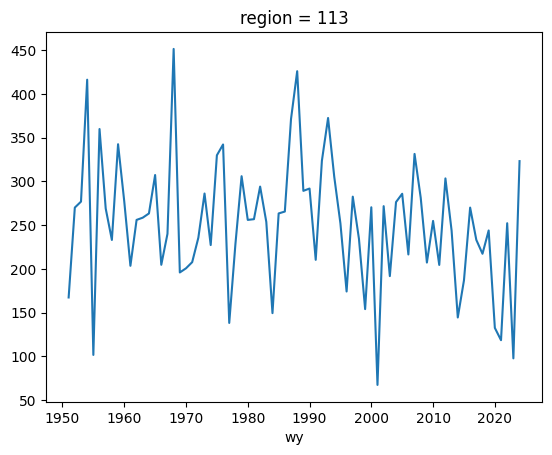

In [18]:
r = swe_peak.region.values[0]
bid = main_ids_valid[int(r)]

print("Example MAIN_BAS:", bid)
print(swe_peak.sel(region=r))
swe_peak.sel(region=r).plot()

In [19]:
# ============================================================
# Basin-level monthly ETo
# ERA5 grid
# ============================================================

SPATIAL_DIM = "z"

eto_s = era5_data["eto"].stack({SPATIAL_DIM: ("lat", "lon")})
w_s_crop = w2d_era5.stack({SPATIAL_DIM: ("lat", "lon")})
crop_s = crop_on_era5.stack({SPATIAL_DIM: ("lat", "lon")})

eto_list = []

for r in eligible_regions:
    basin_mask_s = mask3d_era5.sel(region=r).stack({SPATIAL_DIM: ("lat", "lon")})
    valid_cells = basin_mask_s & crop_s.notnull() & (crop_s > 0)
    idx = np.where(valid_cells.values)[0]
    weights_r = w_s_crop.isel(z=idx) * crop_s.isel(z=idx)
    eto_r = eto_s.isel(z=idx)
    valid_weights = weights_r.where(eto_r.notnull())
    basin_mean = (eto_r * valid_weights).sum(dim="z", skipna=True) / valid_weights.sum(dim="z", skipna=True)
    basin_mean = basin_mean.expand_dims(region=[r])
    eto_list.append(basin_mean)

eto_all = xr.concat(eto_list, dim="region")

print("Basins with ETo:", eto_all.sizes["region"])

Basins with ETo: 169


In [20]:
eto_all = eto_all.assign_coords(wy=water_year(eto_all.time))
is_summer = eto_all.time.dt.month.isin([4, 5, 6, 7, 8, 9])
eto_summer = eto_all.where(is_summer, drop=True).groupby("wy").mean("time", skipna=True)
eto_summer = eto_summer.sel(wy=slice(1951, 2024))

Example MAIN_BAS: 2040005120
<xarray.DataArray (wy: 74)> Size: 592B
array([100.4370264 , 102.90088312,  96.80530028, 102.04040937,
       107.32177349, 100.03211267, 104.98947124, 103.03836091,
        95.5217322 ,  99.33553887, 104.10084817, 107.36018516,
        92.23107051, 100.52135818, 101.27406309, 106.05860848,
        90.15906323,  98.85126281, 105.8852186 , 105.28151691,
       100.32137218,  96.47012809, 101.27292886, 103.6702382 ,
       103.92584714,  98.52559649, 101.35682951, 101.4589274 ,
       101.79478946, 106.51718344,  97.24659045,  96.90442134,
        98.73585151,  96.62891867, 103.38372335, 101.91895798,
       100.77490539,  95.11784132, 108.30057892,  97.84472251,
       101.80422811,  96.4780543 ,  98.08759818, 103.7426664 ,
        97.72013866, 102.60485435, 100.13101043, 108.30613703,
       103.25343138, 107.76888918, 106.71650972, 100.96577318,
       102.2218046 , 101.15067834, 101.2824722 , 107.83113318,
       104.045391  , 103.58106712,  97.11603396, 1

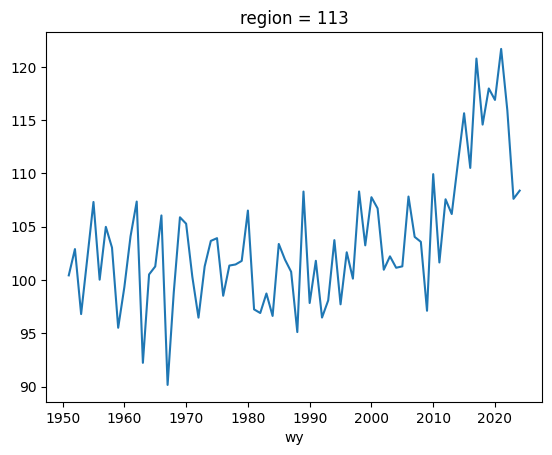

In [21]:
r = eto_summer.region.values[0]
bid = main_ids_valid[int(r)]

print("Example MAIN_BAS:", bid)
print(eto_summer.sel(region=r))
eto_summer.sel(region=r).plot()

In [22]:
q_lo, q_hi = 0.30, 0.70
class_by_basin = {}

common_regions = np.intersect1d(swe_peak.region.values, eto_summer.region.values)

for r in common_regions:

    bid = main_ids_valid[int(r)]

    swe_b = swe_peak.sel(region=r)
    eto_b = eto_summer.sel(region=r)

    common_wy = np.intersect1d(swe_b.wy.values, eto_b.wy.values)

    if len(common_wy) == 0:
        continue

    swe_b = swe_b.sel(wy=common_wy)
    eto_b = eto_b.sel(wy=common_wy)

    valid = np.isfinite(swe_b.values) & np.isfinite(eto_b.values)

    swe_b = swe_b.isel(wy=valid)
    eto_b = eto_b.isel(wy=valid)

    if swe_b.sizes["wy"] == 0:
        continue

    common_wy = swe_b.wy.values.astype(int)

    swe_tlow = float(swe_b.quantile(q_lo, dim="wy"))
    eto_thigh = float(eto_b.quantile(q_hi, dim="wy"))

    low_swe = swe_b <= swe_tlow
    high_eto = eto_b >= eto_thigh

    df_class = pd.DataFrame({
        "WY": common_wy,
        "normal": (~low_swe & ~high_eto).values,
        "low_swe_only": (low_swe & ~high_eto).values,
        "high_eto_only": (~low_swe & high_eto).values,
        "low_swe_high_eto": (low_swe & high_eto).values,
    })

    class_by_basin[bid] = df_class

In [23]:
def wy_values_for_class(df_class, col):
    return df_class.loc[df_class[col], "WY"].astype(int).tolist()

def sel_vals(da, wys):
    if (da is None) or (not wys):
        return np.array([])

    da_wy = da["wy"].values.astype(int)
    wys_ok = np.intersect1d(da_wy, np.array(wys, dtype=int))

    if len(wys_ok) == 0:
        return np.array([])

    out = da.sel(wy=wys_ok).values
    return out[np.isfinite(out)]

precip_by_basin = {}

for bid in main_ids_valid:
    df_class = class_by_basin.get(bid)
    pr_fall = ppt_fall_by_basin.get(bid)
    pr_winter = ppt_winter_by_basin.get(bid)
    pr_summer = ppt_summer_by_basin.get(bid)

    if (df_class is None) or (pr_fall is None) or (pr_winter is None) or (pr_summer is None):
        continue

    wy_normal   = wy_values_for_class(df_class, "normal")
    wy_snowonly = wy_values_for_class(df_class, "low_swe_only")
    wy_demonly  = wy_values_for_class(df_class, "high_eto_only")
    wy_comp     = wy_values_for_class(df_class, "low_swe_high_eto")

    precip_by_basin[bid] = {
        "fall": {
            "normal":      sel_vals(pr_fall, wy_normal),
            "snow_only":   sel_vals(pr_fall, wy_snowonly),
            "demand_only": sel_vals(pr_fall, wy_demonly),
            "compound":    sel_vals(pr_fall, wy_comp),
        },
        "winter": {
            "normal":      sel_vals(pr_winter, wy_normal),
            "snow_only":   sel_vals(pr_winter, wy_snowonly),
            "demand_only": sel_vals(pr_winter, wy_demonly),
            "compound":    sel_vals(pr_winter, wy_comp),
        },
        "summer": {
            "normal":      sel_vals(pr_summer, wy_normal),
            "snow_only":   sel_vals(pr_summer, wy_snowonly),
            "demand_only": sel_vals(pr_summer, wy_demonly),
            "compound":    sel_vals(pr_summer, wy_comp),
        }
    }

print("Basins with precip_by_basin:", len(precip_by_basin))

Basins with precip_by_basin: 169


In [24]:
bid = next(iter(precip_by_basin.keys()))
for season in ["fall", "winter", "summer"]:
    print(season, {k: len(v) for k, v in precip_by_basin[bid][season].items()})


fall {'normal': 38, 'snow_only': 14, 'demand_only': 14, 'compound': 8}
winter {'normal': 38, 'snow_only': 14, 'demand_only': 14, 'compound': 8}
summer {'normal': 38, 'snow_only': 14, 'demand_only': 14, 'compound': 8}


fall {'normal': 38, 'snow_only': 14, 'demand_only': 14, 'compound': 8}
winter {'normal': 38, 'snow_only': 14, 'demand_only': 14, 'compound': 8}
summer {'normal': 38, 'snow_only': 14, 'demand_only': 14, 'compound': 8}


/tmp/ipykernel_1868614/2456469966.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=labels, showfliers=False)


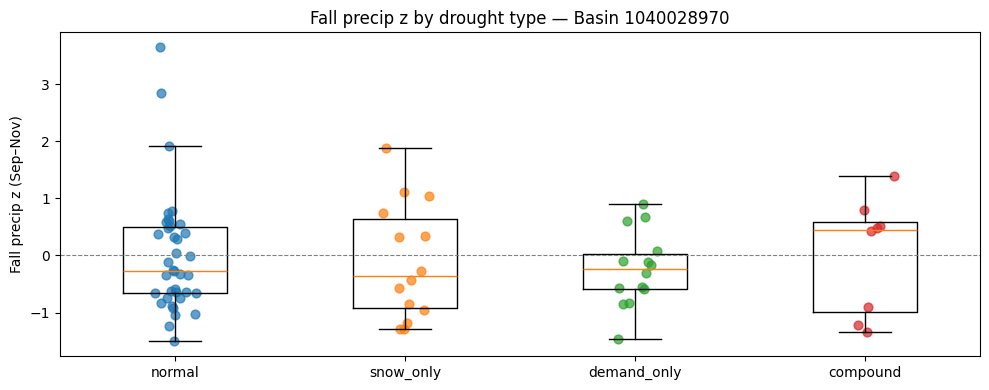

/tmp/ipykernel_1868614/2456469966.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=labels, showfliers=False)


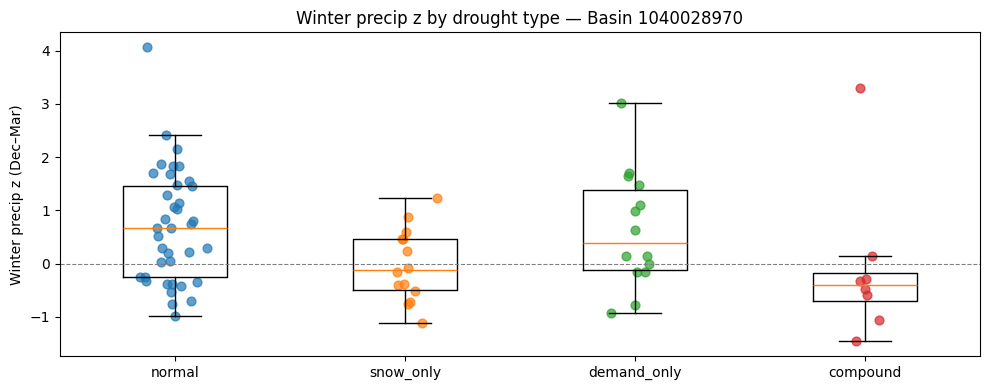

/tmp/ipykernel_1868614/2456469966.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=labels, showfliers=False)


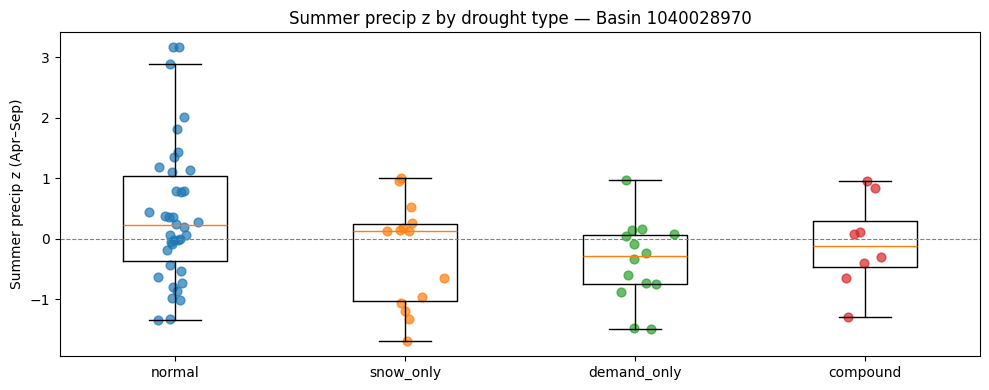

In [25]:
bid = next(iter(precip_by_basin.keys()))
for season in ["fall", "winter", "summer"]:
    print(season, {k: len(v) for k, v in precip_by_basin[bid][season].items()})
labels = ["normal", "snow_only", "demand_only", "compound"]

def box_with_points(season, ylabel, title):
    data = [precip_by_basin[bid][season][k] for k in labels]

    plt.figure(figsize=(10,4))
    plt.boxplot(data, labels=labels, showfliers=False)

    # add individual points with jitter
    for i, y in enumerate(data, start=1):
        if len(y) == 0:
            continue
        x = np.random.normal(i, 0.05, size=len(y))  # jitter
        plt.scatter(x, y, alpha=0.7, s=40)

    plt.axhline(0, color="gray", linestyle="--", linewidth=0.8)
    plt.ylabel(ylabel)
    plt.title(f"{title} — Basin {bid}")
    plt.tight_layout()
    plt.show()

box_with_points("fall",   "Fall precip z (Sep–Nov)",   "Fall precip z by drought type")
box_with_points("winter", "Winter precip z (Dec–Mar)", "Winter precip z by drought type")
box_with_points("summer", "Summer precip z (Apr–Sep)", "Summer precip z by drought type")

/tmp/ipykernel_1868614/2456469966.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=labels, showfliers=False)


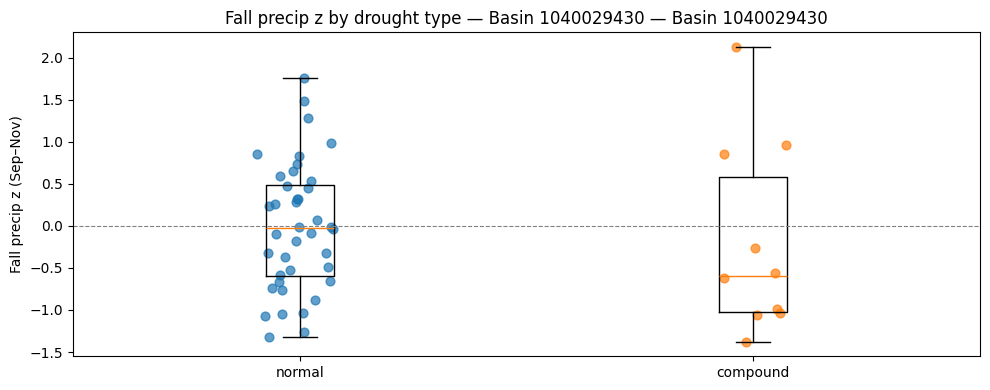

/tmp/ipykernel_1868614/2456469966.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=labels, showfliers=False)


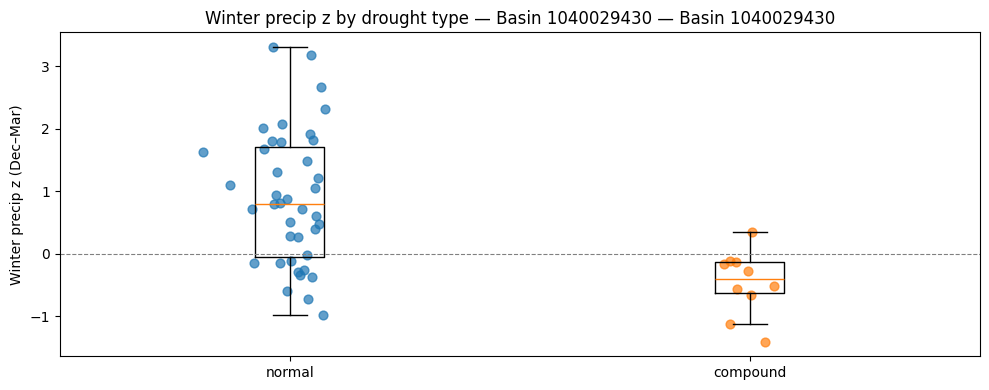

/tmp/ipykernel_1868614/2456469966.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=labels, showfliers=False)


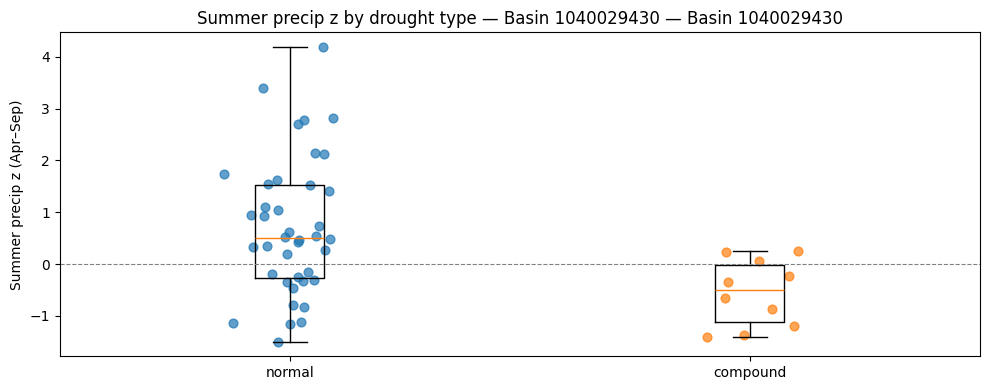

In [26]:
bid = 1040029430
labels = ["normal", "compound"]

if bid not in precip_by_basin:
    print("This basin has no precip data in precip_by_basin.")
else:
    box_with_points("fall",   "Fall precip z (Sep–Nov)",   f"Fall precip z by drought type — Basin {bid}")
    box_with_points("winter", "Winter precip z (Dec–Mar)", f"Winter precip z by drought type — Basin {bid}")
    box_with_points("summer", "Summer precip z (Apr–Sep)", f"Summer precip z by drought type — Basin {bid}")

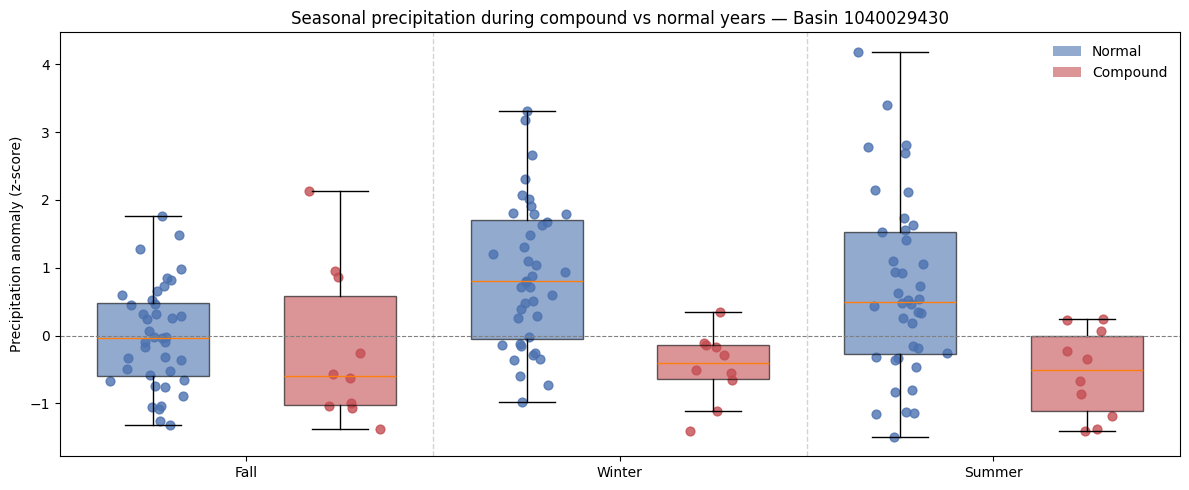

In [27]:
labels = ["normal", "compound"]
seasons = ["fall", "winter", "summer"]

plt.figure(figsize=(12,5))

positions = []
data = []
colors = []
xticks = []
pos = 1

for season in seasons:
    for k in labels:
        arr = precip_by_basin[bid][season][k]
        data.append(arr)
        positions.append(pos)

        # assign colors
        colors.append("#4C72B0" if k == "normal" else "#C44E52")
        pos += 1

    xticks.append(pos - 1.5)

# draw boxplots
bp = plt.boxplot(
    data,
    positions=positions,
    widths=0.6,
    showfliers=False,
    patch_artist=True
)

# color boxes
for patch, c in zip(bp["boxes"], colors):
    patch.set_facecolor(c)
    patch.set_alpha(0.6)

# overlay points with same colors
for p, arr, c in zip(positions, data, colors):
    if len(arr) == 0:
        continue
    x = np.random.normal(p, 0.08, size=len(arr))
    plt.scatter(x, arr, color=c, alpha=0.8, s=40)

# season labels
plt.xticks(xticks, ["Fall", "Winter", "Summer"])

# separators
plt.axvline(2.5, color="lightgray", linestyle="--", linewidth=1)
plt.axvline(4.5, color="lightgray", linestyle="--", linewidth=1)

plt.axhline(0, color="gray", linestyle="--", linewidth=0.8)
plt.ylabel("Precipitation anomaly (z-score)")
plt.title(f"Seasonal precipitation during compound vs normal years — Basin {bid}")

# legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor="#4C72B0", alpha=0.6, label="Normal"),
    Patch(facecolor="#C44E52", alpha=0.6, label="Compound")
]
plt.legend(handles=legend_elements, frameon=False)

plt.tight_layout()
plt.show()

In [28]:
for bid in list(class_by_basin.keys())[:10]:
    df = class_by_basin[bid]
    print(bid, df[["normal","low_swe_only","high_eto_only","low_swe_high_eto"]].sum().to_dict())

1040028970 {'normal': 38, 'low_swe_only': 14, 'high_eto_only': 14, 'low_swe_high_eto': 8}
1040029430 {'normal': 40, 'low_swe_only': 12, 'high_eto_only': 12, 'low_swe_high_eto': 10}
1040029700 {'normal': 41, 'low_swe_only': 11, 'high_eto_only': 11, 'low_swe_high_eto': 11}
2040000010 {'normal': 38, 'low_swe_only': 14, 'high_eto_only': 14, 'low_swe_high_eto': 8}
2040003440 {'normal': 39, 'low_swe_only': 13, 'high_eto_only': 13, 'low_swe_high_eto': 9}
2040003550 {'normal': 41, 'low_swe_only': 11, 'high_eto_only': 11, 'low_swe_high_eto': 11}
2040003560 {'normal': 40, 'low_swe_only': 12, 'high_eto_only': 12, 'low_swe_high_eto': 10}
2040004130 {'normal': 38, 'low_swe_only': 14, 'high_eto_only': 14, 'low_swe_high_eto': 8}
2040004140 {'normal': 40, 'low_swe_only': 12, 'high_eto_only': 12, 'low_swe_high_eto': 10}
2040004280 {'normal': 36, 'low_swe_only': 16, 'high_eto_only': 16, 'low_swe_high_eto': 6}


In [29]:
seasons = ["fall", "winter", "summer"]
classes = ["normal", "snow_only", "demand_only", "compound"]

mech_by_basin = {}

for bid, d in precip_by_basin.items():
    out = {}

    for season in seasons:
        for cls in classes:
            arr = d[season][cls]
            out[f"{season}_mean_{cls}"] = float(np.mean(arr)) if len(arr) > 0 else np.nan
            out[f"n_{season}_{cls}"] = int(len(arr))

    mech_by_basin[bid] = out

# quick peek
some_bid = next(iter(mech_by_basin.keys()))
print(some_bid, mech_by_basin[some_bid])

1040028970 {'fall_mean_normal': 0.008956624743196525, 'n_fall_normal': 38, 'fall_mean_snow_only': -0.10091335434182032, 'n_fall_snow_only': 14, 'fall_mean_demand_only': -0.23482689597155534, 'n_fall_demand_only': 14, 'fall_mean_compound': 0.018426253841731133, 'n_fall_compound': 8, 'winter_mean_normal': 0.6970853626319948, 'n_winter_normal': 38, 'winter_mean_snow_only': -0.020242711717000157, 'n_winter_snow_only': 14, 'winter_mean_demand_only': 0.6294237842188359, 'n_winter_demand_only': 14, 'winter_mean_compound': -0.09424177884833865, 'n_winter_compound': 8, 'summer_mean_normal': 0.3964609482324959, 'n_summer_normal': 38, 'summer_mean_snow_only': -0.2512458297652037, 'n_summer_snow_only': 14, 'summer_mean_demand_only': -0.37038159709391155, 'n_summer_demand_only': 14, 'summer_mean_compound': -0.08080246510871178, 'n_summer_compound': 8}


In [30]:
# Welch t-tests for precip (compound vs normal) by season
seasons = ["fall", "winter", "summer"]
alpha = 0.05

ppt_ttest_results = {}  # ppt_ttest_results[bid][season] = {mean_diff, p_value, n_A, n_B}

for bid, d in precip_by_basin.items():
    basin_res = {}

    for season in seasons:
        a = d[season]["compound"]  # group A
        b = d[season]["normal"]    # group B

        # require at least 2 years per group (same rule as your SWSA code)
        if (len(a) < 2) or (len(b) < 2):
            continue

        tstat, pval = ttest_ind(a, b, equal_var=False, nan_policy="omit")

        basin_res[season] = {
            "mean_diff": float(np.nanmean(a) - np.nanmean(b)),  # compound - normal
            "p_value": float(pval),
            "n_A": int(len(a)),
            "n_B": int(len(b)),
        }

    if basin_res:
        ppt_ttest_results[bid] = basin_res

In [31]:
# Build per-basin Δprecip (compound − normal) + p-value dicts

delta_ppt_by_basin = {s: {} for s in seasons}
p_ppt_by_basin     = {s: {} for s in seasons}

for bid in main_ids_valid:
    res = ppt_ttest_results.get(bid, {})

    for s in seasons:
        if s in res:
            delta_ppt_by_basin[s][bid] = res[s]["mean_diff"]
            p_ppt_by_basin[s][bid]     = res[s]["p_value"]
        else:
            delta_ppt_by_basin[s][bid] = np.nan
            p_ppt_by_basin[s][bid]     = np.nan

In [32]:
basins_diss = hb.dissolve(by="MAIN_BAS").reset_index()
basins_diss["MAIN_BAS"] = basins_diss["MAIN_BAS"].astype(int)

basins_diss["fall_comp"] = basins_diss["MAIN_BAS"].map(
    lambda x: mech_by_basin.get(int(x), {}).get("fall_mean_compound", np.nan)
)
basins_diss["winter_comp"] = basins_diss["MAIN_BAS"].map(
    lambda x: mech_by_basin.get(int(x), {}).get("winter_mean_compound", np.nan)
)
basins_diss["summer_comp"] = basins_diss["MAIN_BAS"].map(
    lambda x: mech_by_basin.get(int(x), {}).get("summer_mean_compound", np.nan)
)
basins_diss["n_comp"] = basins_diss["MAIN_BAS"].map(
    lambda x: mech_by_basin.get(int(x), {}).get("n_winter_compound", 0)
)

basins_diss["fall_norm"] = basins_diss["MAIN_BAS"].map(
    lambda x: mech_by_basin.get(int(x), {}).get("fall_mean_normal", np.nan)
)
basins_diss["winter_norm"] = basins_diss["MAIN_BAS"].map(
    lambda x: mech_by_basin.get(int(x), {}).get("winter_mean_normal", np.nan)
)
basins_diss["summer_norm"] = basins_diss["MAIN_BAS"].map(
    lambda x: mech_by_basin.get(int(x), {}).get("summer_mean_normal", np.nan)
)

basins_diss["n_norm"] = basins_diss["MAIN_BAS"].map(
    lambda x: mech_by_basin.get(int(x), {}).get("n_winter_normal", 0)
)

print(basins_diss[["fall_comp","winter_comp","summer_comp"]].notna().sum())

fall_comp      169
winter_comp    169
summer_comp    169
dtype: int64


In [33]:
basins_diss["dPPT_fall_comp_minus_norm"]   = basins_diss["MAIN_BAS"].map(delta_ppt_by_basin["fall"])
basins_diss["dPPT_winter_comp_minus_norm"] = basins_diss["MAIN_BAS"].map(delta_ppt_by_basin["winter"])
basins_diss["dPPT_summer_comp_minus_norm"] = basins_diss["MAIN_BAS"].map(delta_ppt_by_basin["summer"])

In [34]:
print("Basins total:", len(basins_diss))
print("fall_comp notna:", basins_diss["fall_comp"].notna().sum())
print("winter_comp notna:", basins_diss["winter_comp"].notna().sum())
print("summer_comp notna:", basins_diss["summer_comp"].notna().sum())
print("fall_norm notna:", basins_diss["fall_norm"].notna().sum())
print("winter_norm notna:", basins_diss["winter_norm"].notna().sum())
print("summer_norm notna:", basins_diss["summer_norm"].notna().sum())

Basins total: 602
fall_comp notna: 169
winter_comp notna: 169
summer_comp notna: 169
fall_norm notna: 169
winter_norm notna: 169
summer_norm notna: 169


In [35]:
basins_diss.loc[basins_diss["n_comp"] == 0, "fall_comp"] = np.nan
basins_diss.loc[basins_diss["n_comp"] == 0, "winter_comp"] = np.nan
basins_diss.loc[basins_diss["n_comp"] == 0, "summer_comp"] = np.nan
basins_diss.loc[basins_diss["n_norm"] == 0, "fall_norm"] = np.nan
basins_diss.loc[basins_diss["n_norm"] == 0, "winter_norm"] = np.nan
basins_diss.loc[basins_diss["n_norm"] == 0, "summer_norm"] = np.nan

In [36]:
def plot_global_delta_ppt(column, title, p_dict=None, alpha=0.05):
    valid = basins_diss[basins_diss[column].notna()]
    if valid.empty:
        print(f"No data to plot for {column}")
        return

    vmin, vmax = -2.5, 2.5
    bounds = np.arange(vmin, vmax + 0.25, 0.25)
    n_bins = len(bounds) - 1

    cmap = plt.get_cmap("BrBG", n_bins)
    norm = mcolors.BoundaryNorm(bounds, ncolors=n_bins)

    fig = plt.figure(figsize=(12, 6))
    ax = plt.axes(projection=ccrs.Robinson())
    ax.set_global()

    ax.add_feature(cfeature.BORDERS, linewidth=0.6, edgecolor="gray")
    ax.add_feature(cfeature.COASTLINE, linewidth=0.6)

    basins_diss.plot(
        ax=ax,
        column=column,
        cmap=cmap,
        norm=norm,
        edgecolor="black",
        linewidth=0.2,
        legend=False,
        transform=ccrs.PlateCarree(),
        missing_kwds={
            "color": "lightgray",
            "edgecolor": "black",
            "label": "Insufficient data"
        },
    )

    if p_dict is not None:
        sig_ids = [
            bid for bid, p in p_dict.items()
            if (p is not None) and np.isfinite(p) and (p < alpha)
        ]
        print(f"{len(sig_ids)} significant basins (p < {alpha}) for {title}")

        sig_gdf = basins_diss[basins_diss["MAIN_BAS"].isin(sig_ids)]
        if not sig_gdf.empty:
            sig_gdf.plot(
                ax=ax,
                facecolor="none",
                edgecolor="black",
                linewidth=0.4,
                hatch="///",
                transform=ccrs.PlateCarree()
            )

            hatch_patch = mpatches.Patch(
                facecolor="none",
                edgecolor="black",
                hatch="///",
                label=f"p < {alpha}"
            )
            ax.legend(handles=[hatch_patch], loc="lower left",
                      bbox_to_anchor=(0.02, 0.02), frameon=False)

    ax.set_title(title, fontsize=14, pad=10)
    ax.set_extent([-180, 180, 0, 70], crs=ccrs.PlateCarree())

    # place colorbar relative to map axes
    fig.canvas.draw()
    pos = ax.get_position()
    cax = fig.add_axes([pos.x0 + 0.03, pos.y0 - 0.10, pos.width - 0.12, 0.035])

    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cb = fig.colorbar(sm, cax=cax, orientation="horizontal", ticks=bounds)
    cb.set_label("ΔPrecip (z-score) = Cascading − No-drought")

    plt.subplots_adjust(top=0.92, bottom=0.08, left=0.02, right=0.98)
    plt.show()

34 significant basins (p < 0.05) for ΔPrecip Anomaly (Fall, Sep–Nov): Cascading − No-drought


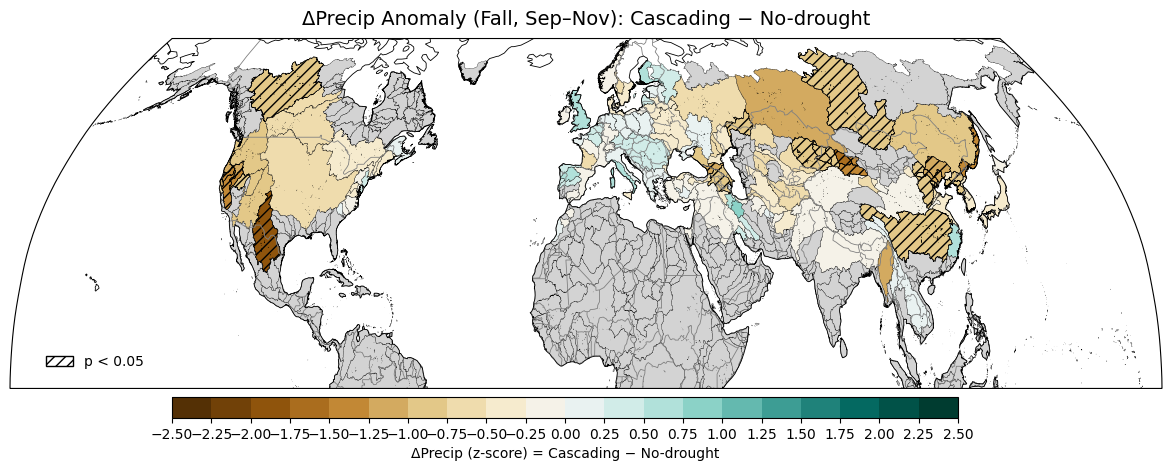

In [37]:
plot_global_delta_ppt(
    "dPPT_fall_comp_minus_norm",
    "ΔPrecip Anomaly (Fall, Sep–Nov): Cascading − No-drought",
    p_dict=p_ppt_by_basin["fall"],
    alpha=0.05
)

102 significant basins (p < 0.05) for ΔPrecip Anomaly (Winter, Dec–Mar): Cascading − No-drought


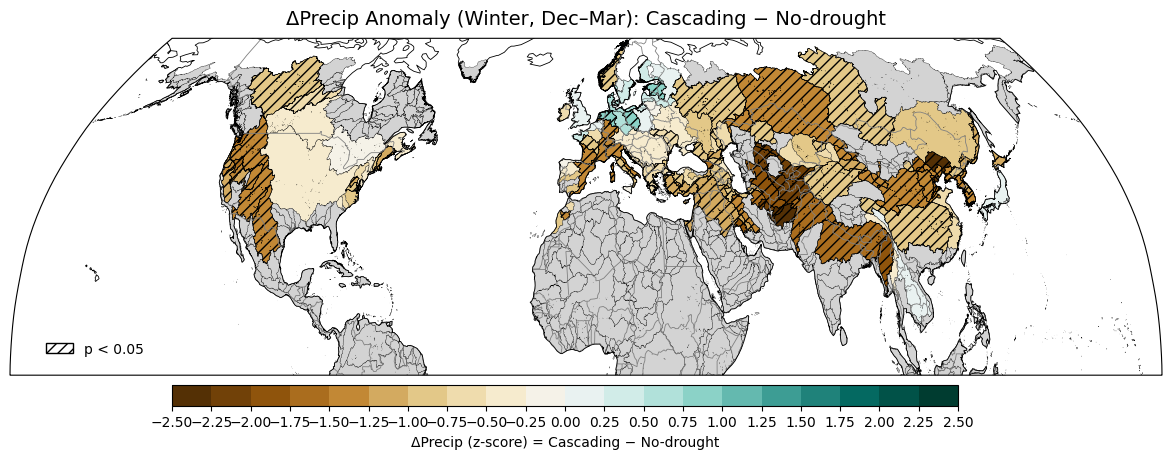

In [38]:
plot_global_delta_ppt(
    "dPPT_winter_comp_minus_norm",
    "ΔPrecip Anomaly (Winter, Dec–Mar): Cascading − No-drought",
    p_dict=p_ppt_by_basin["winter"],
    alpha=0.05
)

128 significant basins (p < 0.05) for ΔPrecip Anomaly (Summer, Apr–Sep): Cascading − No-drought


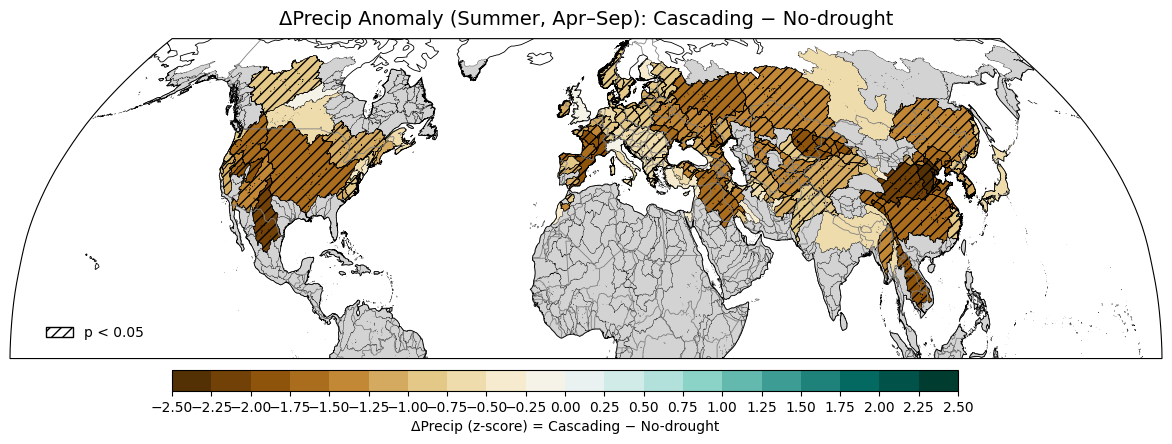

In [39]:
plot_global_delta_ppt(
    "dPPT_summer_comp_minus_norm",
    "ΔPrecip Anomaly (Summer, Apr–Sep): Cascading − No-drought",
    p_dict=p_ppt_by_basin["summer"],
    alpha=0.05
)

Winter stats:
{'n_valid': 169, 'n_sig': 102, 'n_inc': 6, 'n_dec': 96, 'pct_sig': 60.35502958579882, 'pct_inc': 3.5502958579881656, 'pct_dec': 56.80473372781065}

Summer stats:
{'n_valid': 169, 'n_sig': 128, 'n_inc': 0, 'n_dec': 128, 'pct_sig': 75.7396449704142, 'pct_inc': 0.0, 'pct_dec': 75.7396449704142}
Saved figure to: /home/mgurazada/snowdroughts_thirst/code/certain/Fig_3_1.png


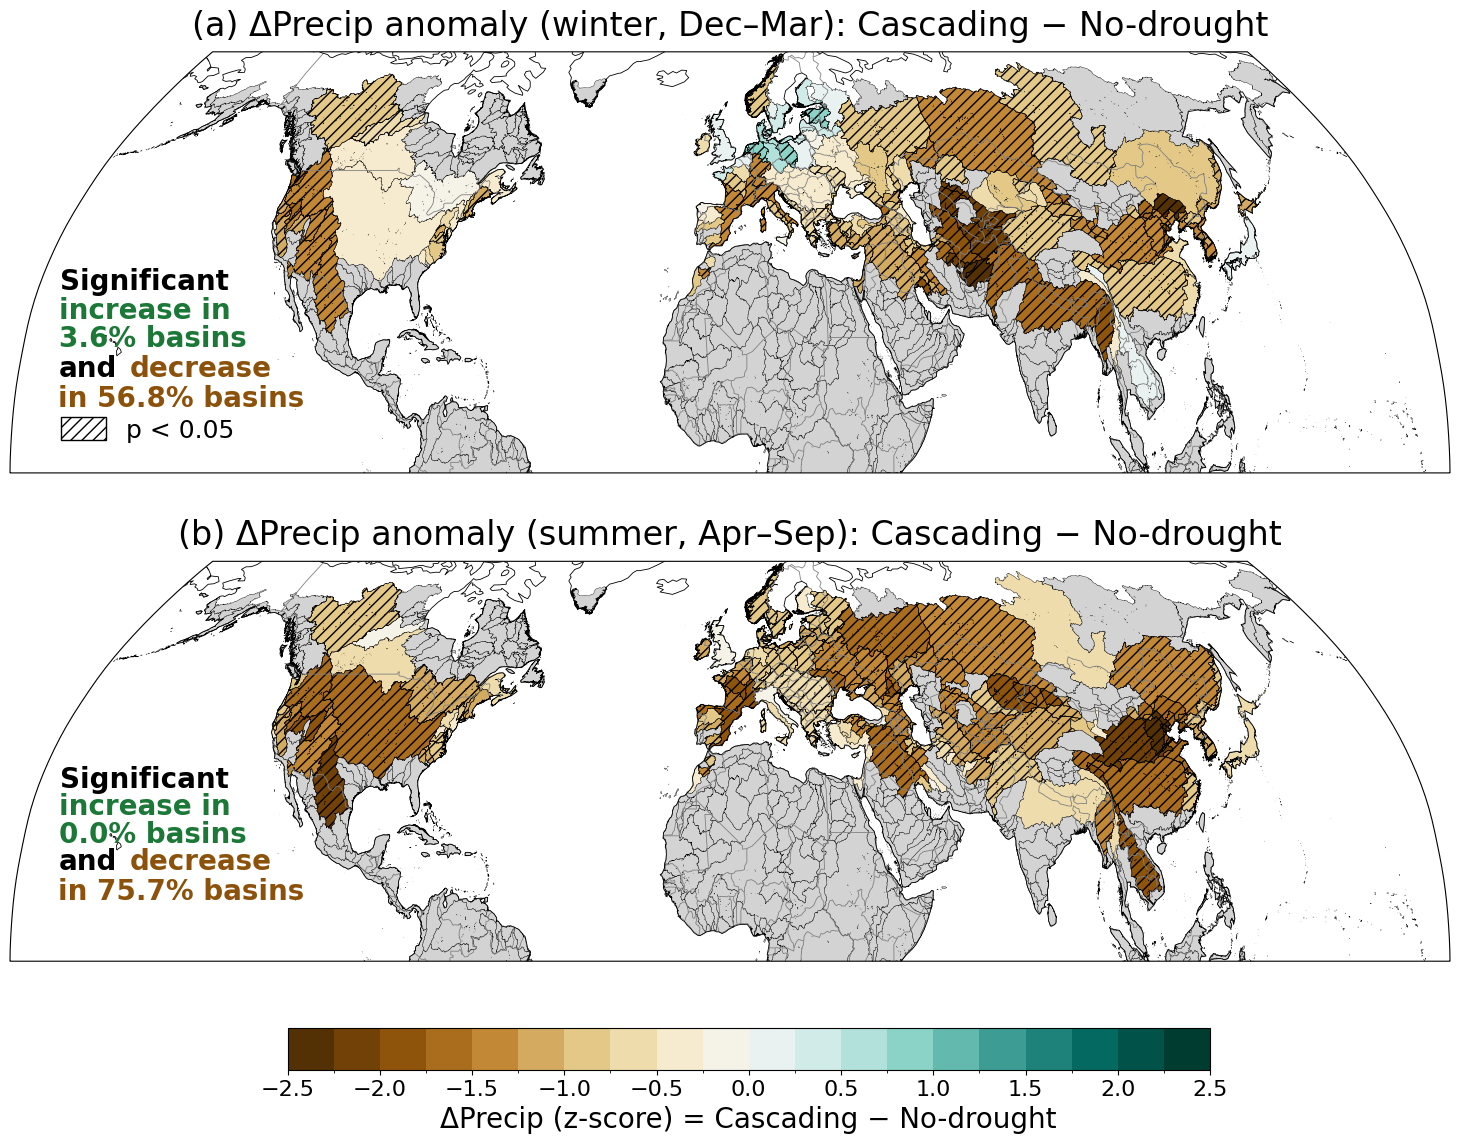

In [40]:
import os
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# ------------------------------------------------------------
# Helper: count significant positive / negative basins
# Percentages are relative to basins with non-missing values
# in the plotted column for that season.
# ------------------------------------------------------------
def get_sig_stats(gdf, column, p_dict, alpha=0.05):
    pvals = gdf["MAIN_BAS"].map(p_dict)

    valid = gdf[column].notna()
    sig = valid & pvals.notna() & (pvals < alpha)

    sig_inc = sig & (gdf[column] > 0)
    sig_dec = sig & (gdf[column] < 0)

    n_valid = int(valid.sum())
    n_sig = int(sig.sum())
    n_inc = int(sig_inc.sum())
    n_dec = int(sig_dec.sum())

    pct_sig = 100 * n_sig / n_valid if n_valid > 0 else np.nan
    pct_inc = 100 * n_inc / n_valid if n_valid > 0 else np.nan
    pct_dec = 100 * n_dec / n_valid if n_valid > 0 else np.nan

    return {
        "n_valid": n_valid,
        "n_sig": n_sig,
        "n_inc": n_inc,
        "n_dec": n_dec,
        "pct_sig": pct_sig,
        "pct_inc": pct_inc,
        "pct_dec": pct_dec,
    }


# ------------------------------------------------------------
# Panel plotting function
# ------------------------------------------------------------
def plot_delta_ppt_panels_vertical(
    gdf,
    winter_col="dPPT_winter_comp_minus_norm",
    summer_col="dPPT_summer_comp_minus_norm",
    winter_pdict=None,
    summer_pdict=None,
    alpha=0.05,
    outname="Fig_3_1.png"
):
    # shared color scale
    vmin, vmax = -2.5, 2.5
    bounds = np.arange(vmin, vmax + 0.25, 0.25)
    tick_vals = np.arange(vmin, vmax + 0.5, 0.5)

    cmap = plt.get_cmap("BrBG", len(bounds) - 1)
    norm = mcolors.BoundaryNorm(bounds, ncolors=cmap.N, clip=True)

    # stats
    winter_stats = get_sig_stats(gdf, winter_col, winter_pdict, alpha=alpha)
    summer_stats = get_sig_stats(gdf, summer_col, summer_pdict, alpha=alpha)

    print("Winter stats:")
    print(winter_stats)
    print("\nSummer stats:")
    print(summer_stats)

    # larger figure
    fig, axes = plt.subplots(
        nrows=2,
        ncols=1,
        figsize=(15, 13),
        subplot_kw={"projection": ccrs.Robinson()}
    )

    # font sizes
    title_fs = 24
    annotation_fs = 20
    legend_fs = 18
    cbar_label_fs = 20
    cbar_tick_fs = 16

    panel_info = [
        (
            axes[0],
            winter_col,
            winter_pdict,
            "(a) ΔPrecip anomaly (winter, Dec–Mar): Cascading − No-drought",
            winter_stats
        ),
        (
            axes[1],
            summer_col,
            summer_pdict,
            "(b) ΔPrecip anomaly (summer, Apr–Sep): Cascading − No-drought",
            summer_stats
        )
    ]

    for i, (ax, column, p_dict, title, stats) in enumerate(panel_info):
        ax.set_global()

        ax.add_feature(cfeature.BORDERS, linewidth=0.6, edgecolor="gray")
        ax.add_feature(cfeature.COASTLINE, linewidth=0.6)

        # main polygons
        gdf.plot(
            ax=ax,
            column=column,
            cmap=cmap,
            norm=norm,
            edgecolor="black",
            linewidth=0.25,
            legend=False,
            transform=ccrs.PlateCarree(),
            missing_kwds={
                "color": "lightgray",
                "edgecolor": "black"
            },
        )

        # hatching for significance
        if p_dict is not None:
            sig_ids = [
                bid for bid, p in p_dict.items()
                if (p is not None) and np.isfinite(p) and (p < alpha)
            ]

            sig_gdf = gdf[gdf["MAIN_BAS"].isin(sig_ids) & gdf[column].notna()]

            if not sig_gdf.empty:
                sig_gdf.plot(
                    ax=ax,
                    facecolor="none",
                    edgecolor="black",
                    linewidth=0.3,
                    hatch="///",
                    transform=ccrs.PlateCarree()
                )

        ax.set_title(title, fontsize=title_fs, pad=12)
        ax.set_extent([-180, 180, 0, 70], crs=ccrs.PlateCarree())

        # one compact significance block
        x_text = -172
        
        # Significant
        ax.text(
            x_text-3, 31,
            "Significant",
            transform=ccrs.PlateCarree(),
            fontsize=annotation_fs,
            color="black",
            ha="left",
            va="center",
            fontweight="bold"
        )
        
        # increase block
        ax.text(
            x_text, 24,
            f"increase in\n{stats['pct_inc']:.1f}% basins",
            transform=ccrs.PlateCarree(),
            fontsize=annotation_fs,
            color="#1b7837",
            ha="left",
            va="center",
            fontweight="bold",
            linespacing=1.0
        )
        
        # "and decrease in" on same line
        y_dec = 18
        
        ax.text(
            x_text+2, y_dec-1,
            "and",
            transform=ccrs.PlateCarree(),
            fontsize=annotation_fs,
            color="black",
            ha="left",
            va="center",
            fontweight="bold"
        )
        
        ax.text(
            x_text + 20, y_dec-1,   # shift right so it sits on same line after "and"
            "decrease",
            transform=ccrs.PlateCarree(),
            fontsize=annotation_fs,
            color="#8c510a",
            ha="left",
            va="center",
            fontweight="bold"
        )
        
        # second line for decrease %
        ax.text(
            x_text + 3, y_dec-6,
            f"in {stats['pct_dec']:.1f}% basins",
            transform=ccrs.PlateCarree(),
            fontsize=annotation_fs,
            color="#8c510a",
            ha="left",
            va="center",
            fontweight="bold"
        )

        # hatch legend only once
        if i == 0:
            hatch_patch = mpatches.Patch(
                facecolor="white",
                edgecolor="black",
                hatch="///",
                label=f"p < {alpha}"
            )

            ax.legend(
                handles=[hatch_patch],
                loc="lower left",
                bbox_to_anchor=(0.02, 0.02),
                frameon=False,
                fontsize=legend_fs,
                handlelength=1.8,
                handleheight=1.0
            )

    # shared colorbar under bottom panel
    fig.canvas.draw()
    pos2 = axes[1].get_position()

    cax = fig.add_axes([
        pos2.x0 + 0.08,
        pos2.y0 - 0.055,
        pos2.width - 0.16,
        0.032
    ])

    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])

    cb = fig.colorbar(
        sm,
        cax=cax,
        orientation="horizontal",
        boundaries=bounds,
        ticks=tick_vals,
        spacing="proportional"
    )

    cb.set_label(
        "ΔPrecip (z-score) = Cascading − No-drought",
        fontsize=cbar_label_fs
    )
    cb.ax.tick_params(labelsize=cbar_tick_fs)

    plt.subplots_adjust(
        top=0.95,
        bottom=0.12,
        left=0.02,
        right=0.98,
        hspace=-0.14
    )

    # save
    outpath = os.path.abspath(outname)
    fig.savefig(outpath, dpi=300, bbox_inches="tight", facecolor="white")
    print(f"Saved figure to: {outpath}")

    plt.show()


plot_delta_ppt_panels_vertical(
    basins_diss,
    winter_col="dPPT_winter_comp_minus_norm",
    summer_col="dPPT_summer_comp_minus_norm",
    winter_pdict=p_ppt_by_basin["winter"],
    summer_pdict=p_ppt_by_basin["summer"],
    alpha=0.05,
    outname="Fig_3_1.png"
)

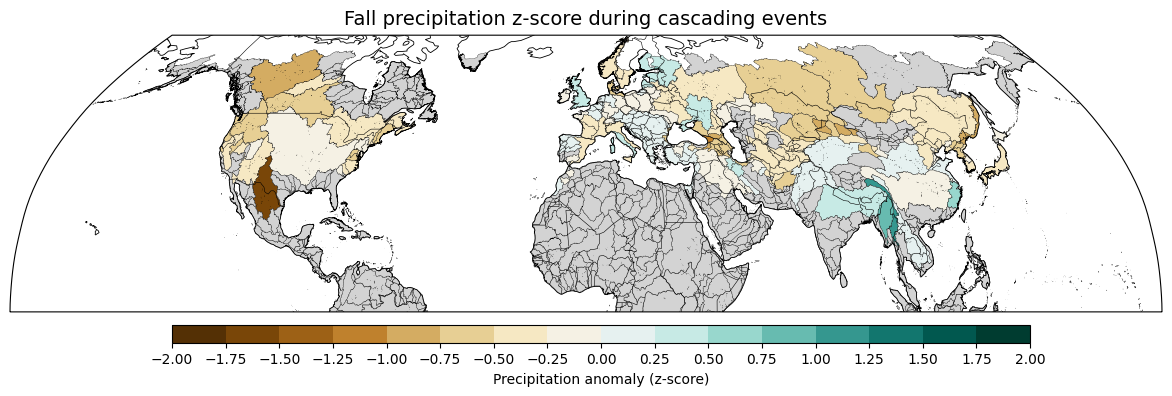

In [41]:
bounds = np.arange(-2, 2.25, 0.25)
cmap = plt.get_cmap("BrBG", len(bounds) - 1)
norm = mcolors.BoundaryNorm(bounds, cmap.N)

fig = plt.figure(figsize=(12, 5))
ax = plt.axes(projection=ccrs.Robinson())
ax.set_global()

ax.add_feature(cfeature.COASTLINE, linewidth=0.6)
ax.add_feature(cfeature.BORDERS, linewidth=0.4)

basins_diss.plot(
    ax=ax,
    column="fall_comp",
    cmap=cmap,
    norm=norm,
    edgecolor="black",
    linewidth=0.2,
    legend=False,
    transform=ccrs.PlateCarree(),
    missing_kwds={
        "color": "lightgray",
        "edgecolor": "black"
    }
)

ax.set_title(
    "Fall precipitation z-score during cascading events",
    fontsize=14,
    pad=8
)

ax.set_extent([-180, 180, 0, 70], crs=ccrs.PlateCarree())

# consistent colorbar placement relative to map
fig.canvas.draw()
pos = ax.get_position()
cax = fig.add_axes([pos.x0 + 0.03, pos.y0 - 0.12, pos.width - 0.06, 0.035])

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cb = fig.colorbar(sm, cax=cax, orientation="horizontal", ticks=bounds)
cb.set_label("Precipitation anomaly (z-score)")

plt.subplots_adjust(top=0.90, bottom=0.08, left=0.02, right=0.98)
plt.show()

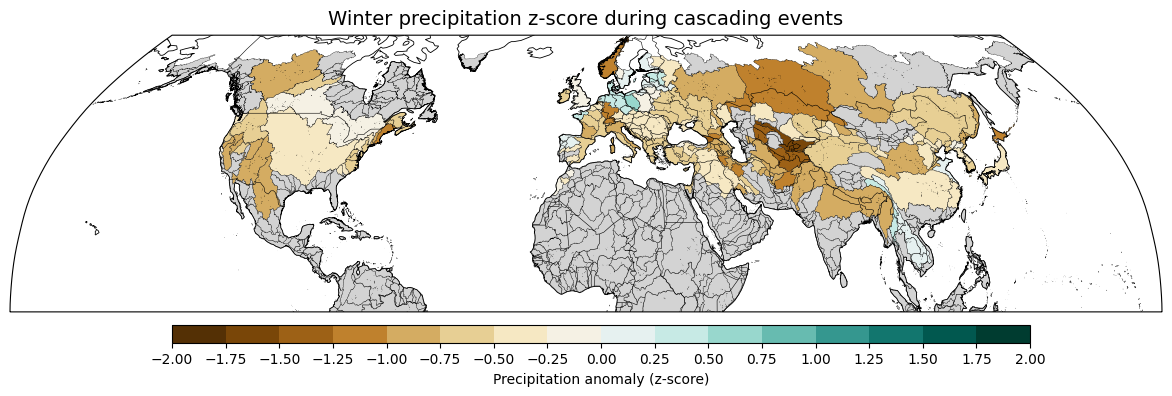

In [42]:
bounds = np.arange(-2, 2.25, 0.25)
cmap = plt.get_cmap("BrBG", len(bounds) - 1)
norm = mcolors.BoundaryNorm(bounds, cmap.N)

fig = plt.figure(figsize=(12, 5))
ax = plt.axes(projection=ccrs.Robinson())
ax.set_global()

ax.add_feature(cfeature.COASTLINE, linewidth=0.6)
ax.add_feature(cfeature.BORDERS, linewidth=0.4)

basins_diss.plot(
    ax=ax,
    column="winter_comp",
    cmap=cmap,
    norm=norm,
    edgecolor="black",
    linewidth=0.2,
    legend=False,
    transform=ccrs.PlateCarree(),
    missing_kwds={
        "color": "lightgray",
        "edgecolor": "black"
    }
)

ax.set_title(
    "Winter precipitation z-score during cascading events",
    fontsize=14,
    pad=8
)

ax.set_extent([-180, 180, 0, 70], crs=ccrs.PlateCarree())

# consistent colorbar placement relative to map
fig.canvas.draw()
pos = ax.get_position()
cax = fig.add_axes([pos.x0 + 0.03, pos.y0 - 0.12, pos.width - 0.06, 0.035])

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cb = fig.colorbar(sm, cax=cax, orientation="horizontal", ticks=bounds)
cb.set_label("Precipitation anomaly (z-score)")

plt.subplots_adjust(top=0.90, bottom=0.08, left=0.02, right=0.98)
plt.show()

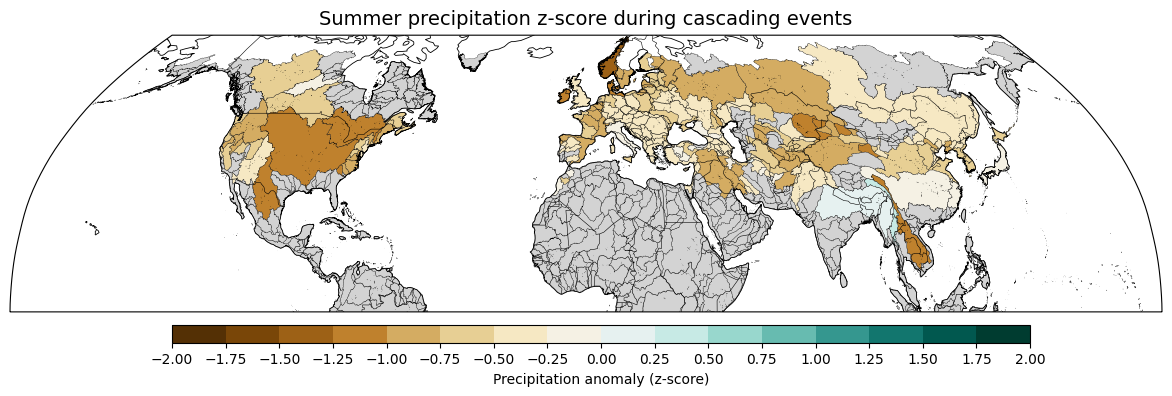

In [43]:
bounds = np.arange(-2, 2.25, 0.25)
cmap = plt.get_cmap("BrBG", len(bounds) - 1)
norm = mcolors.BoundaryNorm(bounds, cmap.N)

fig = plt.figure(figsize=(12, 5))
ax = plt.axes(projection=ccrs.Robinson())
ax.set_global()

ax.add_feature(cfeature.COASTLINE, linewidth=0.6)
ax.add_feature(cfeature.BORDERS, linewidth=0.4)

basins_diss.plot(
    ax=ax,
    column="summer_comp",
    cmap=cmap,
    norm=norm,
    edgecolor="black",
    linewidth=0.2,
    legend=False,
    transform=ccrs.PlateCarree(),
    missing_kwds={
        "color": "lightgray",
        "edgecolor": "black"
    }
)

ax.set_title(
    "Summer precipitation z-score during cascading events",
    fontsize=14,
    pad=8
)

ax.set_extent([-180, 180, 0, 70], crs=ccrs.PlateCarree())

# consistent colorbar placement relative to map
fig.canvas.draw()
pos = ax.get_position()
cax = fig.add_axes([pos.x0 + 0.03, pos.y0 - 0.12, pos.width - 0.06, 0.035])

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cb = fig.colorbar(sm, cax=cax, orientation="horizontal", ticks=bounds)
cb.set_label("Precipitation anomaly (z-score)")

plt.subplots_adjust(top=0.90, bottom=0.08, left=0.02, right=0.98)
plt.show()

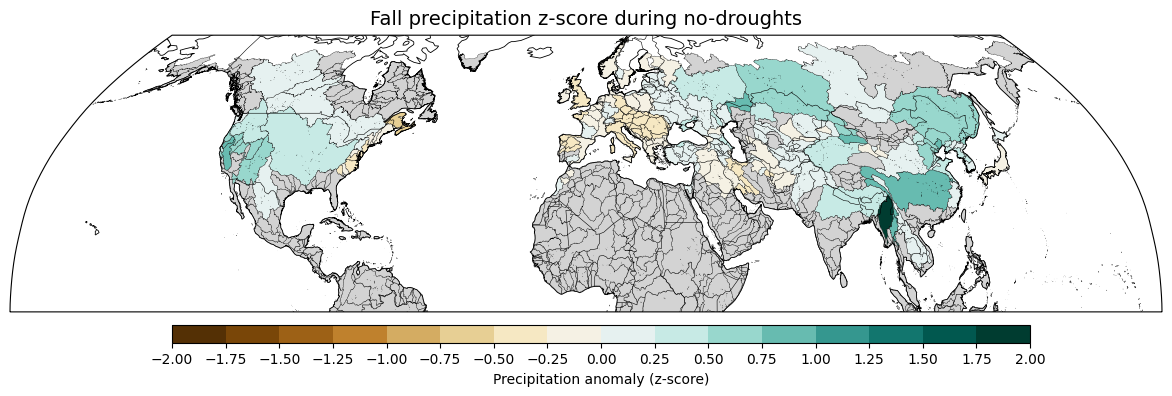

In [44]:
bounds = np.arange(-2, 2.25, 0.25)
cmap = plt.get_cmap("BrBG", len(bounds) - 1)
norm = mcolors.BoundaryNorm(bounds, cmap.N)

fig = plt.figure(figsize=(12, 5))
ax = plt.axes(projection=ccrs.Robinson())
ax.set_global()

ax.add_feature(cfeature.COASTLINE, linewidth=0.6)
ax.add_feature(cfeature.BORDERS, linewidth=0.4)

basins_diss.plot(
    ax=ax,
    column="fall_norm",
    cmap=cmap,
    norm=norm,
    edgecolor="black",
    linewidth=0.2,
    legend=False,
    transform=ccrs.PlateCarree(),
    missing_kwds={
        "color": "lightgray",
        "edgecolor": "black"
    }
)

ax.set_title(
    "Fall precipitation z-score during no-droughts",
    fontsize=14,
    pad=8
)

ax.set_extent([-180, 180, 0, 70], crs=ccrs.PlateCarree())

# consistent colorbar placement relative to map
fig.canvas.draw()
pos = ax.get_position()
cax = fig.add_axes([pos.x0 + 0.03, pos.y0 - 0.12, pos.width - 0.06, 0.035])

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cb = fig.colorbar(sm, cax=cax, orientation="horizontal", ticks=bounds)
cb.set_label("Precipitation anomaly (z-score)")

plt.subplots_adjust(top=0.90, bottom=0.08, left=0.02, right=0.98)
plt.show()

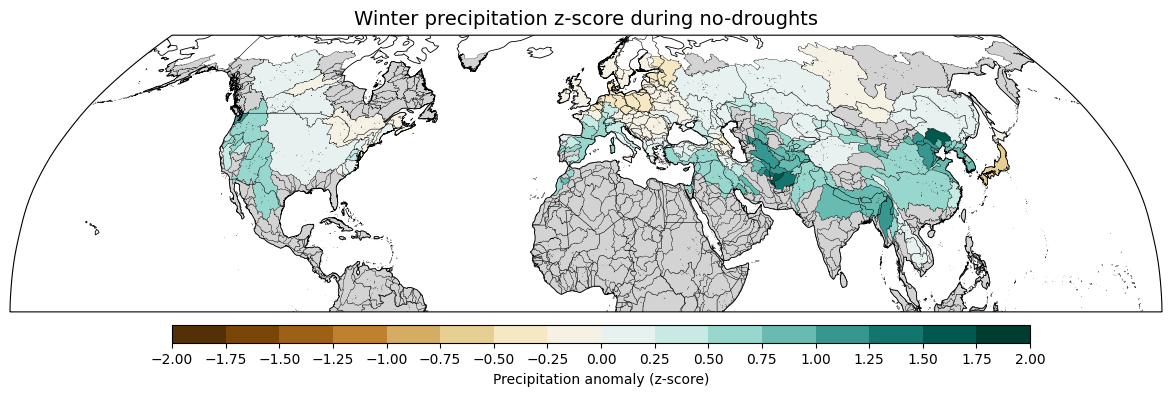

In [45]:
bounds = np.arange(-2, 2.25, 0.25)
cmap = plt.get_cmap("BrBG", len(bounds) - 1)
norm = mcolors.BoundaryNorm(bounds, cmap.N)

fig = plt.figure(figsize=(12, 5))
ax = plt.axes(projection=ccrs.Robinson())
ax.set_global()

ax.add_feature(cfeature.COASTLINE, linewidth=0.6)
ax.add_feature(cfeature.BORDERS, linewidth=0.4)

basins_diss.plot(
    ax=ax,
    column="winter_norm",
    cmap=cmap,
    norm=norm,
    edgecolor="black",
    linewidth=0.2,
    legend=False,
    transform=ccrs.PlateCarree(),
    missing_kwds={
        "color": "lightgray",
        "edgecolor": "black"
    }
)

ax.set_title(
    "Winter precipitation z-score during no-droughts",
    fontsize=14,
    pad=8
)

ax.set_extent([-180, 180, 0, 70], crs=ccrs.PlateCarree())

# consistent colorbar placement relative to map
fig.canvas.draw()
pos = ax.get_position()
cax = fig.add_axes([pos.x0 + 0.03, pos.y0 - 0.12, pos.width - 0.06, 0.035])

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cb = fig.colorbar(sm, cax=cax, orientation="horizontal", ticks=bounds)
cb.set_label("Precipitation anomaly (z-score)")

plt.subplots_adjust(top=0.90, bottom=0.08, left=0.02, right=0.98)
plt.show()

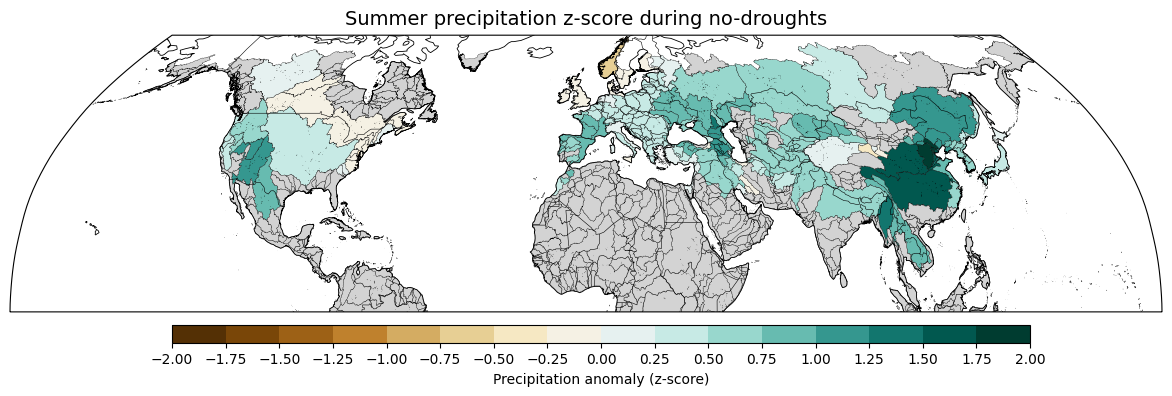

In [46]:
bounds = np.arange(-2, 2.25, 0.25)
cmap = plt.get_cmap("BrBG", len(bounds) - 1)
norm = mcolors.BoundaryNorm(bounds, cmap.N)

fig = plt.figure(figsize=(12, 5))
ax = plt.axes(projection=ccrs.Robinson())
ax.set_global()

ax.add_feature(cfeature.COASTLINE, linewidth=0.6)
ax.add_feature(cfeature.BORDERS, linewidth=0.4)

basins_diss.plot(
    ax=ax,
    column="summer_norm",
    cmap=cmap,
    norm=norm,
    edgecolor="black",
    linewidth=0.2,
    legend=False,
    transform=ccrs.PlateCarree(),
    missing_kwds={
        "color": "lightgray",
        "edgecolor": "black"
    }
)

ax.set_title(
    "Summer precipitation z-score during no-droughts",
    fontsize=14,
    pad=8
)

ax.set_extent([-180, 180, 0, 70], crs=ccrs.PlateCarree())

# consistent colorbar placement relative to map
fig.canvas.draw()
pos = ax.get_position()
cax = fig.add_axes([pos.x0 + 0.03, pos.y0 - 0.12, pos.width - 0.06, 0.035])

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cb = fig.colorbar(sm, cax=cax, orientation="horizontal", ticks=bounds)
cb.set_label("Precipitation anomaly (z-score)")

plt.subplots_adjust(top=0.90, bottom=0.08, left=0.02, right=0.98)
plt.show()

In [47]:
out_dir = "conditional_prob_inputs"
os.makedirs(out_dir, exist_ok=True)

# save winter precip basin-year data
with open(os.path.join(out_dir, "ppt_winter_by_basin.pkl"), "wb") as f:
    pickle.dump(ppt_winter_by_basin, f)

# save basin ID order
basin_lookup = pd.DataFrame({
    "region": mask3d_era5.region.values,
    "MAIN_BAS": main_ids_valid
})

basin_lookup.to_csv(os.path.join(out_dir, "basin_region_lookup.csv"), index=False)
print("Saved precip inputs")

Saved precip inputs


In [48]:
ppt_winter_fraction_by_basin = {}

for bid in main_ids_valid:
    pr_ts = ppt_by_basin.get(bid)
    if pr_ts is None:
        continue

    pr_ts = pr_ts.assign_coords(wy=water_year(pr_ts.time))

    # winter / water-year annual
    is_winter = pr_ts.time.dt.month.isin([10, 11, 12, 1, 2, 3])
    pr_winter = pr_ts.where(is_winter, drop=True).groupby("wy").sum("time")
    pr_annual = pr_ts.groupby("wy").sum("time")
    
    pr_winter = pr_winter.sel(wy=slice(1951, 2024))
    pr_annual = pr_annual.sel(wy=slice(1951, 2024))

    f_winter = pr_winter / pr_annual

    # climatological mean fraction per basin
    ppt_winter_fraction_by_basin[bid] = f_winter.mean("wy", skipna=True)

In [49]:
basins_diss["winter_frac"] = np.nan
basins_diss["winter_frac_pct"] = basins_diss["winter_frac"] * 100

for bid, val in ppt_winter_fraction_by_basin.items():
    if val is not None:
        basins_diss.loc[
            basins_diss["HYBAS_ID"] == bid,
            "winter_frac_pct"
        ] = float(val.values) * 100

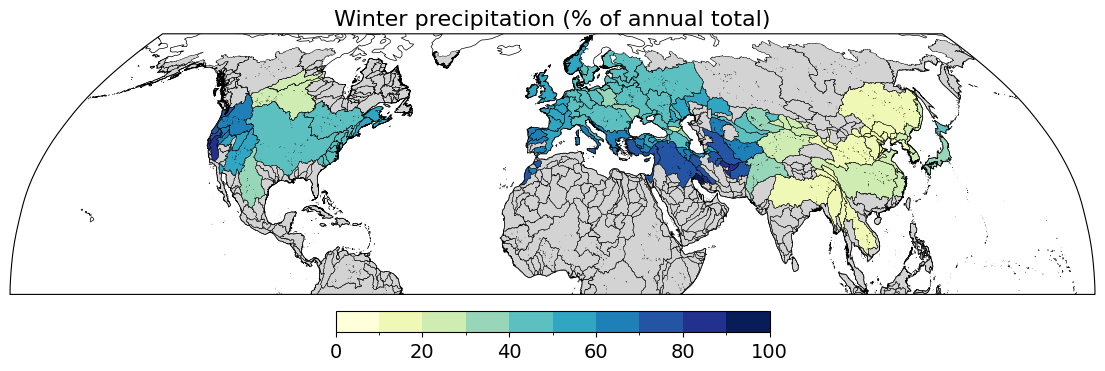

In [51]:
fig = plt.figure(figsize=(14,7))
ax = plt.axes(projection=ccrs.Robinson())
ax.set_global()

bins = np.arange(0, 101, 10)

cmap = plt.get_cmap("YlGnBu", len(bins)-1)

norm = mcolors.BoundaryNorm(
    boundaries=bins,
    ncolors=cmap.N,
    clip=True
)

basins_diss.plot(
    column="winter_frac_pct",
    cmap=cmap,
    norm=norm,
    linewidth=0.2,
    edgecolor="black",
    transform=ccrs.PlateCarree(),
    missing_kwds={"color":"lightgray"},
    ax=ax
)

basins_diss.boundary.plot(
    ax=ax,
    linewidth=0.15,
    color="black",
    transform=ccrs.PlateCarree()
)

ax.set_extent([-180, 180, 0, 70], crs=ccrs.PlateCarree())
ax.coastlines(linewidth=0.5)

cb = plt.colorbar(
    plt.cm.ScalarMappable(norm=norm, cmap=cmap),
    ax=ax,
    orientation="horizontal",
    pad=0.03,
    shrink=0.4
)
cb.ax.tick_params(labelsize=14)

plt.title("Winter precipitation (% of annual total)", fontsize=16)
plt.savefig("Fig_S17.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()